# Blur and Scrambling: People vs. Vision Models
**Stimuli generation + model pipeline** (Colab notebook, T4 GPU is enough)

Project question: *which kinds of image damage break vision models and people together, and which break only one of them?*

This notebook covers the **computer-vision half** of the proposal:

1. Environment setup, seeds
2. Quick, Draw! stroke data -> 224 px line drawings (disjoint train / val / test)
3. Damage pipeline: Gaussian **blur** (3 levels) and offset **tile shuffling** (3 grid sizes), with logged seeds so humans and models see identical instances
4. Frozen encoders: **CLIP ViT-L/14** and **DINOv2 ViT-B/14**
5. One shared **linear probe per model**, trained on **intact** images only
6. 10-way accuracy for every condition, bootstrap CIs, and the two-panel figure

**Conditions: 7 in total** = 1 intact baseline + 3 blur levels + 3 shuffle levels (the outline said "8", but 1 + 3 + 3 = 7; change `BLUR_SIGMAS` / `SHUFFLE_GRIDS` in the config cell if you want more levels).

| Family | Low | Medium | High |
|---|---|---|---|
| Blur (Gaussian sigma, px) | 2 | 5 | 10 |
| Shuffle (grid -> tiles) | 2x2 -> 4 | 4x4 -> 16 | 8x8 -> 64 |

Design notes: 224 = 16 x 14, so the image is exactly 16 x 16 patches for both patch-14 ViTs. Tile sizes are 112 / 56 / 28 px (all multiples of 14). The shuffle grid is shifted by **7 px (half a patch)** so tile borders never line up with patch borders.

## Section 1: Environment setup & imports

In [1]:
# Required packages (torch, transformers, scipy, pandas, matplotlib, tqdm, requests) are pre-installed in the GPU environment


In [2]:
import os, json, random, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import torch
import torch.nn as nn
from PIL import Image, ImageDraw
from scipy.ndimage import gaussian_filter
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

BASE_SEED = 1234

def set_seed(seed: int = BASE_SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(BASE_SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only (feature extraction will be slow; use Runtime > Change runtime type > T4 GPU)")

Device: cuda | NVIDIA L40S


### Configuration
Everything that defines the experiment lives here. Freeze it before collecting human data.

In [3]:
# ---- Categories: 10 familiar English words (available in Quick, Draw!) ----
CATEGORIES = ["airplane", "bicycle", "car", "cat", "chair",
              "clock", "fish", "house", "tree", "umbrella"]
LABEL_OF = {c: i for i, c in enumerate(CATEGORIES)}

# ---- Geometry ----
IMG_SIZE = 224        # 16 x 16 patches of 14 px
PATCH    = 14
OFFSET   = PATCH // 2 # 7 px grid offset for shuffling
MARGIN   = 20         # white border (px) around the drawing; must be > OFFSET
STROKE_W = 4          # line width in px at 224 resolution

# ---- Split sizes (per category) ----
POOL_PER_CAT = 3000   # drawings streamed from each ndjson file
N_TRAIN, N_VAL, N_TEST = 500, 100, 100

# ---- Damage levels ----
BLUR_SIGMAS   = {"low": 2, "medium": 5, "high": 10}   # Gaussian sigma in px
SHUFFLE_GRIDS = {"low": 2, "medium": 4, "high": 8}    # grid x grid tiles

CONDITIONS = [dict(name="intact", family="intact", level="none", param=0)]
CONDITIONS += [dict(name=f"blur_{lv}", family="blur", level=lv, param=s) for lv, s in BLUR_SIGMAS.items()]
CONDITIONS += [dict(name=f"shuffle_{lv}", family="shuffle", level=lv, param=g) for lv, g in SHUFFLE_GRIDS.items()]
COND_NAMES = [c["name"] for c in CONDITIONS]

# ---- Human experiment subset ----
HUMAN_PER_CAT = 7     # 7 images/category x 10 categories = 70 images; 7 conditions -> 10 trials/condition/person
N_PARTICIPANTS = 21   # 3 Groups (G1, G2, G3) x 7 Latin-square Slices (S1..S7)

# ---- Sanity checks on the design ----
assert IMG_SIZE % PATCH == 0
assert MARGIN > OFFSET
for g in SHUFFLE_GRIDS.values():
    assert IMG_SIZE % g == 0 and (IMG_SIZE // g) % PATCH == 0, f"grid {g} does not align with {PATCH}px patches"

OUT_DIR   = Path("./project_outputs");  OUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR = Path("./cache");    CACHE_DIR.mkdir(parents=True, exist_ok=True)
print(len(CONDITIONS), "conditions:", COND_NAMES)

7 conditions: ['intact', 'blur_low', 'blur_medium', 'blur_high', 'shuffle_low', 'shuffle_medium', 'shuffle_high']


## Section 2: Dataset acquisition & preprocessing
We stream the first `POOL_PER_CAT` drawings of each **simplified** Quick, Draw! file (CC BY 4.0) instead of downloading the multi-hundred-MB files.
We **do not** filter on the `recognized` flag (it comes from a model and would bias a human-vs-model comparison); it is only stored for reference.
Strokes are scaled to fit the canvas and **centred on the canvas centre (112, 112)**, which is a patch boundary (8 x 14).

In [4]:
QD_URL = "https://storage.googleapis.com/quickdraw_dataset/full/simplified/{cat}.ndjson"

def fetch_category(cat: str, n: int = POOL_PER_CAT):
    cache = CACHE_DIR / f"{cat}.json"
    if cache.exists():
        return json.load(open(cache))
    rows = []
    with requests.get(QD_URL.format(cat=cat), stream=True, timeout=120) as r:
        r.raise_for_status()
        for line in r.iter_lines():
            if not line:
                continue
            d = json.loads(line)
            rows.append(dict(key_id=str(d["key_id"]), countrycode=d.get("countrycode"),
                             recognized=d.get("recognized"), drawing=d["drawing"]))
            if len(rows) >= n:
                break
    json.dump(rows, open(cache, "w"))
    return rows

raw = {cat: fetch_category(cat) for cat in tqdm(CATEGORIES, desc="Downloading")}
print({c: len(v) for c, v in raw.items()})

{'airplane': 3000, 'bicycle': 3000, 'car': 3000, 'cat': 3000, 'chair': 3000, 'clock': 3000, 'fish': 3000, 'house': 3000, 'tree': 3000, 'umbrella': 3000}


In [5]:
def render_drawing(drawing, size=IMG_SIZE, margin=MARGIN, stroke=STROKE_W, ss=4):
    # Render Quick, Draw! strokes as a black-on-white uint8 image (size x size), centred, anti-aliased.
    pts = np.concatenate([np.stack([np.asarray(s[0], float), np.asarray(s[1], float)], 1) for s in drawing])
    mn, mx = pts.min(0), pts.max(0)
    span = (mx - mn).max()
    if span <= 0:
        return None                                   # degenerate (single dot): skip
    scale = (size - 2 * margin) / span
    ctr = (mn + mx) / 2

    def tf(x, y):                                     # bbox centre -> canvas centre
        return ((x - ctr[0]) * scale + size / 2) * ss, ((y - ctr[1]) * scale + size / 2) * ss

    canvas = Image.new("L", (size * ss, size * ss), 255)
    d = ImageDraw.Draw(canvas)
    w = stroke * ss
    for s in drawing:
        xy = [tf(x, y) for x, y in zip(s[0], s[1])]
        if len(xy) > 1:
            d.line(xy, fill=0, width=w)
        for x, y in xy:                               # round joints / caps
            d.ellipse([x - w / 2, y - w / 2, x + w / 2, y + w / 2], fill=0)
    return np.asarray(canvas.resize((size, size), Image.LANCZOS), dtype=np.uint8)


def build_split(rows, n_train, n_val, n_test, seed):
    # Shuffle, render, and split into DISJOINT train / val / test.
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(rows))
    out, need = [], n_train + n_val + n_test
    for i in order:
        img = render_drawing(rows[i]["drawing"])
        if img is not None:
            out.append((rows[i], img))
        if len(out) == need:
            break
    assert len(out) == need, "not enough usable drawings; raise POOL_PER_CAT"
    return {"train": out[:n_train], "val": out[n_train:n_train + n_val], "test": out[n_train + n_val:]}

arrays = {s: [] for s in ["train", "val", "test"]}
meta   = {s: [] for s in ["train", "val", "test"]}
for ci, cat in enumerate(CATEGORIES):
    sp = build_split(raw[cat], N_TRAIN, N_VAL, N_TEST, seed=BASE_SEED + ci)
    for split, items in sp.items():
        for rowd, img in items:
            arrays[split].append(img)
            meta[split].append(dict(category=cat, label=ci, key_id=rowd["key_id"],
                                    countrycode=rowd["countrycode"], recognized=rowd["recognized"]))

X = {s: np.stack(v) for s, v in arrays.items()}
M = {s: pd.DataFrame(v) for s, v in meta.items()}
M["test"].insert(0, "uid", np.arange(len(M["test"])))     # stable image id used by models AND humans
y = {s: M[s]["label"].values for s in M}

# Disjointness + balance checks
keys = {s: set(zip(M[s].category, M[s].key_id)) for s in M}
assert not (keys["train"] & keys["val"]) and not (keys["train"] & keys["test"]) and not (keys["val"] & keys["test"])
for s in X:
    print(s, X[s].shape, "per-class counts:", np.bincount(y[s]).tolist())
# Margin check: the 7 px roll used for shuffling must never wrap ink around the border
for s in X:
    b = np.concatenate([X[s][:, :OFFSET].ravel(), X[s][:, -OFFSET:].ravel(),
                        X[s][:, :, :OFFSET].ravel(), X[s][:, :, -OFFSET:].ravel()])
    assert b.min() == 255, "ink inside the border margin"

train (5000, 224, 224) per-class counts: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]
val (1000, 224, 224) per-class counts: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
test (1000, 224, 224) per-class counts: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]


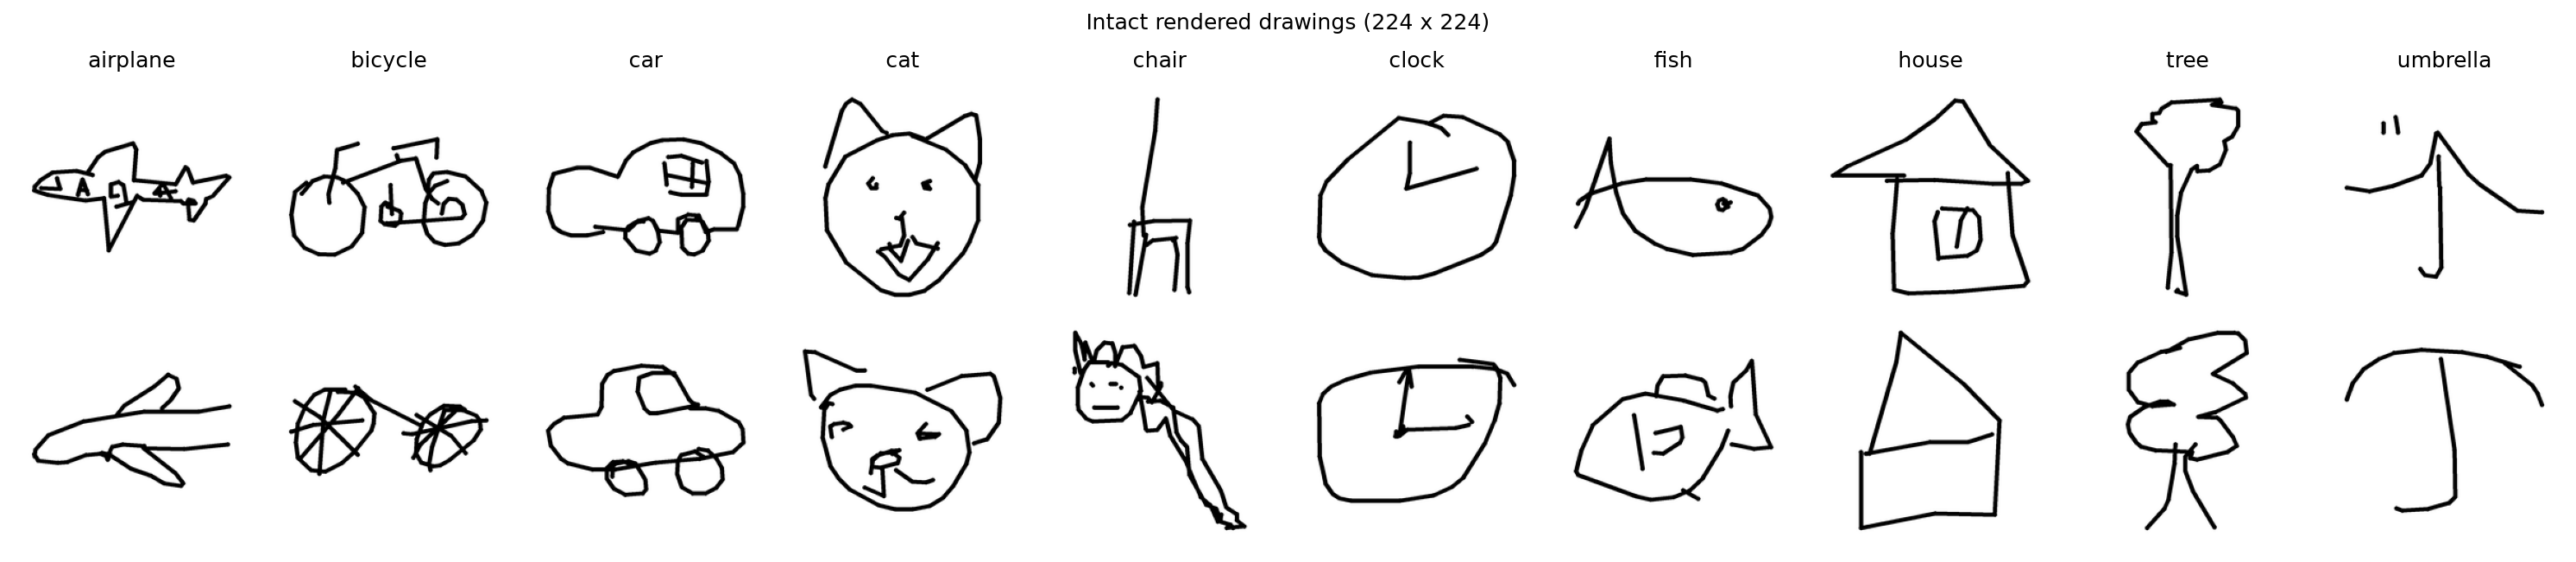

In [6]:
fig, axes = plt.subplots(2, 10, figsize=(20, 4.4))
for j, cat in enumerate(CATEGORIES):
    idx = np.where(y["train"] == j)[0][:2]
    for r, i in enumerate(idx):
        axes[r, j].imshow(X["train"][i], cmap="gray", vmin=0, vmax=255)
        axes[r, j].axis("off")
        if r == 0: axes[r, j].set_title(cat)
plt.suptitle("Intact rendered drawings (224 x 224)"); plt.tight_layout(); plt.show()

## Section 3: Damage pipeline (stimuli generation)
* **Blur**: Gaussian filter, sigma in {2, 5, 10} px (white padding at the borders).
* **Tile shuffle**: image rolled by 7 px, cut into `g x g` tiles, tiles permuted with a **derangement** (no tile stays in place), rolled back. Tile borders therefore sit half a patch off the ViT patch grid. Because of the white margin nothing wraps.
* Every (image, condition) gets a deterministic **seed** derived from `(BASE_SEED, image uid, condition index)`. Seeds, permutations, and the **fraction of tiles containing ink** are logged in a manifest, so models and humans evaluate identical instances.

In [7]:
def blur_image(img, sigma):
    out = gaussian_filter(img.astype(np.float32), sigma=sigma, mode="constant", cval=255.0)
    return np.clip(np.rint(out), 0, 255).astype(np.uint8)


def shuffle_tiles(img, grid, seed, offset=OFFSET, ink_thresh=250):
    # Offset tile shuffle. Returns (image, permutation, fraction of tiles that contain ink).
    rng = np.random.default_rng(seed)
    n, t = grid * grid, img.shape[0] // grid
    rolled = np.roll(img, (offset, offset), axis=(0, 1))
    tiles = [rolled[r * t:(r + 1) * t, c * t:(c + 1) * t] for r in range(grid) for c in range(grid)]
    while True:                                           # derangement: every tile moves
        perm = rng.permutation(n)
        if not np.any(perm == np.arange(n)):
            break
    out = np.empty_like(rolled)
    for dst, src in enumerate(perm):
        r, c = divmod(dst, grid)
        out[r * t:(r + 1) * t, c * t:(c + 1) * t] = tiles[src]
    out = np.roll(out, (-offset, -offset), axis=(0, 1))
    ink_frac = float(np.mean([(tile < ink_thresh).any() for tile in tiles]))
    return out, perm, ink_frac


def stim_seed(uid: int, cond_idx: int) -> int:
    return int(np.random.SeedSequence([BASE_SEED, int(uid), int(cond_idx)]).generate_state(1)[0])


def apply_condition(img, cond, seed):
    # Returns (damaged image, info dict).
    if cond["family"] == "intact":
        return img.copy(), dict(perm=None, ink_tile_frac=np.nan)
    if cond["family"] == "blur":
        return blur_image(img, cond["param"]), dict(perm=None, ink_tile_frac=np.nan)
    out, perm, ink = shuffle_tiles(img, cond["param"], seed)
    return out, dict(perm=" ".join(map(str, perm)), ink_tile_frac=ink)

# Quick unit tests
_t = X["test"][0]
a, pa, _ = shuffle_tiles(_t, 4, seed=1); b, pb, _ = shuffle_tiles(_t, 4, seed=1)
assert np.array_equal(a, b) and np.array_equal(pa, pb), "shuffle must be reproducible"
assert sorted(a.ravel().tolist()) == sorted(_t.ravel().tolist()), "shuffle must preserve pixels"
print("damage functions OK")

damage functions OK


In [8]:
test_imgs = X["test"]
stimuli = {c["name"]: np.empty_like(test_imgs) for c in CONDITIONS}
rows = []
for uid in tqdm(range(len(test_imgs)), desc="Generating stimuli"):
    for ci, cond in enumerate(CONDITIONS):
        seed = stim_seed(uid, ci)
        img, info = apply_condition(test_imgs[uid], cond, seed)
        stimuli[cond["name"]][uid] = img
        rows.append(dict(uid=uid, category=M["test"].category[uid], label=int(y["test"][uid]),
                         key_id=M["test"].key_id[uid], condition=cond["name"], family=cond["family"],
                         level=cond["level"], param=cond["param"], seed=seed,
                         ink_tile_frac=info["ink_tile_frac"], perm=info["perm"]))
manifest = pd.DataFrame(rows)
manifest.to_csv(OUT_DIR / "stimuli_manifest.csv", index=False)
print(manifest.shape, "| conditions:", manifest.condition.nunique())
manifest.groupby("condition").ink_tile_frac.mean().round(3)

(7000, 11) | conditions: 7


condition
blur_high           NaN
blur_low            NaN
blur_medium         NaN
intact              NaN
shuffle_high      0.448
shuffle_low       0.982
shuffle_medium    0.706
Name: ink_tile_frac, dtype: float64

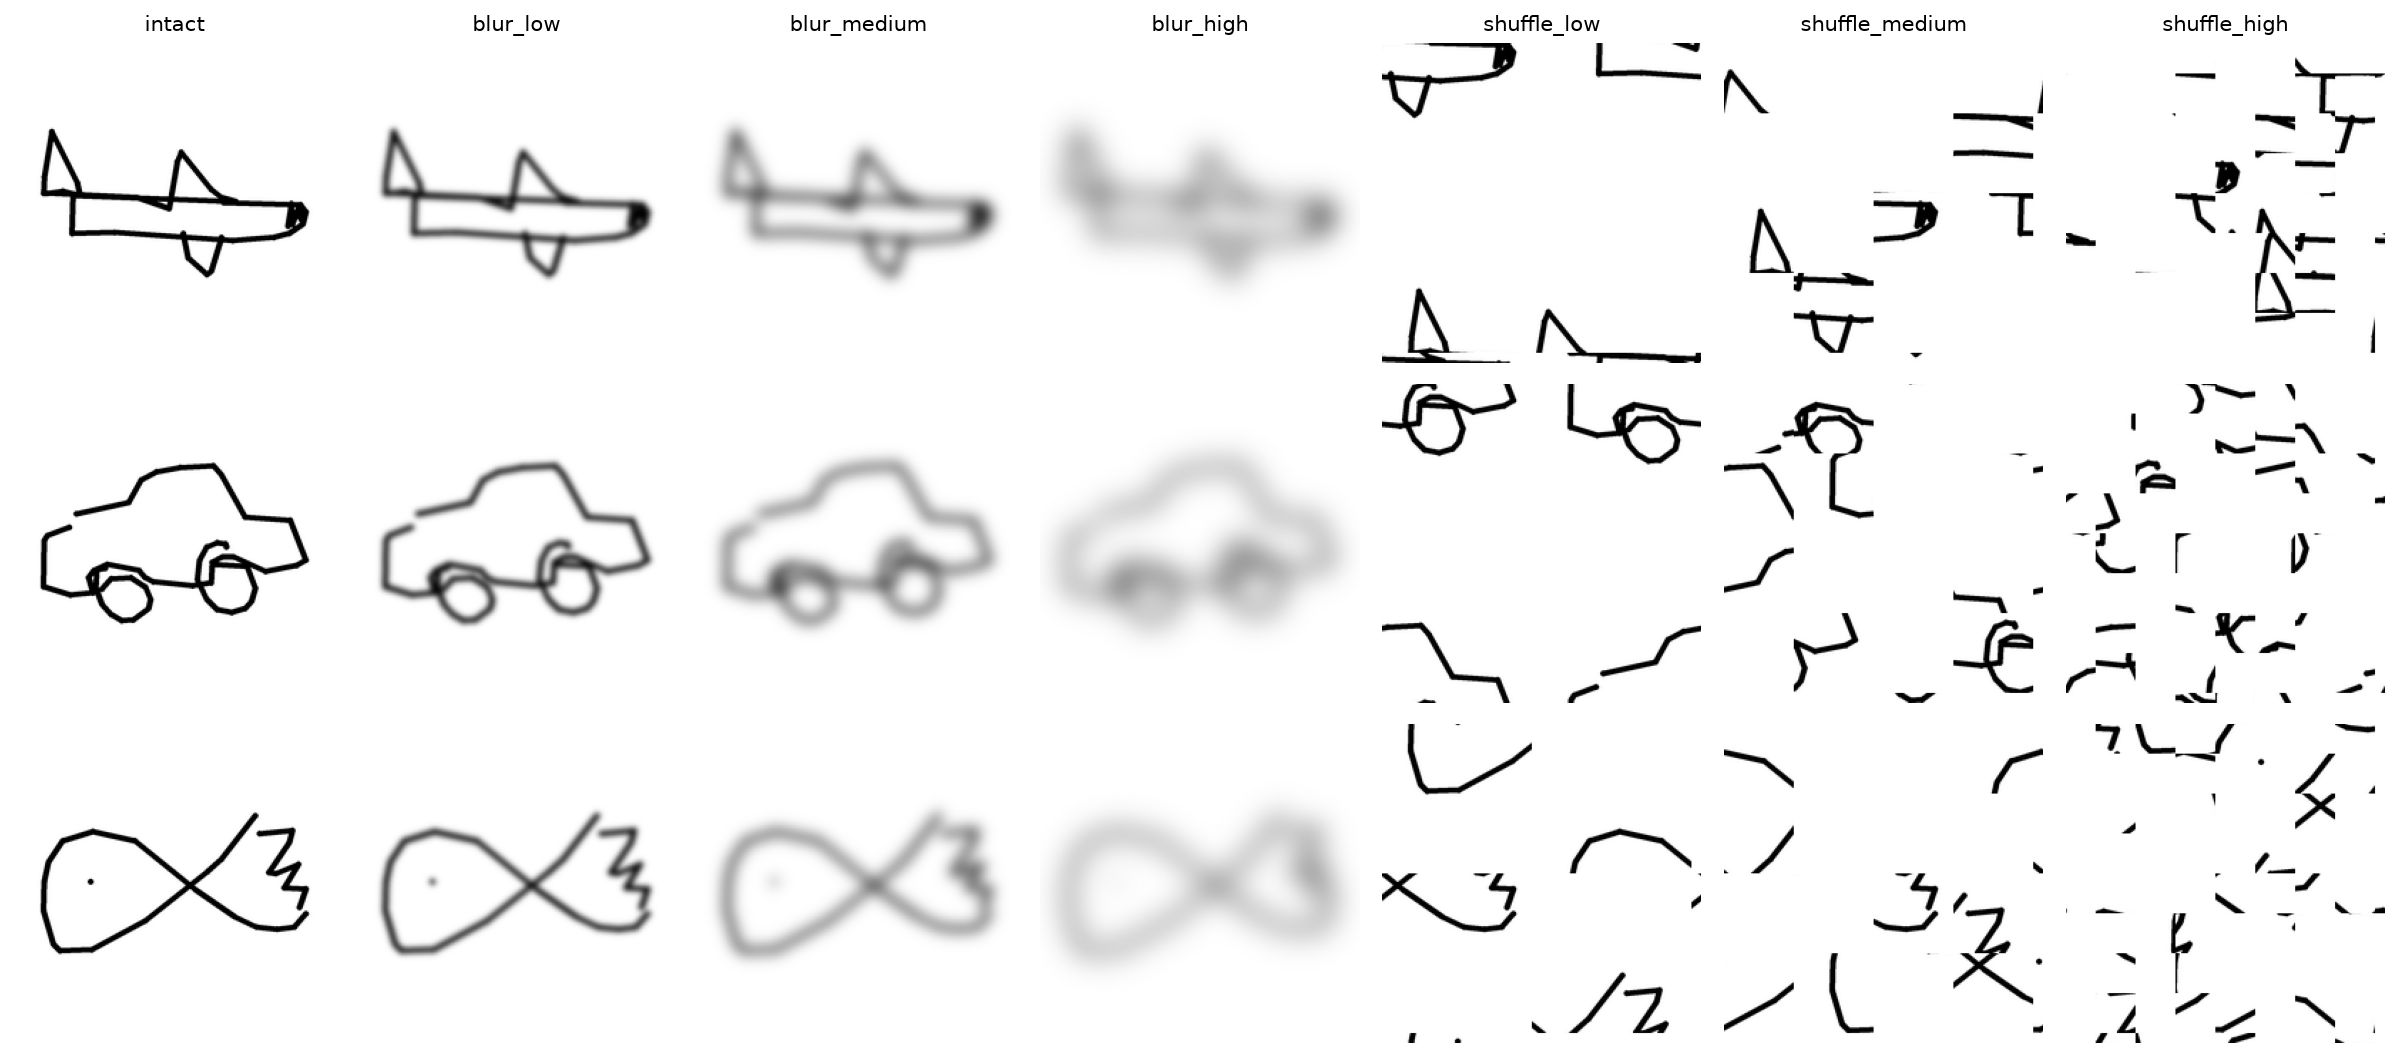

In [9]:
show_uids = [0, 250, 600]
fig, axes = plt.subplots(len(show_uids), len(CONDITIONS), figsize=(2.3 * len(CONDITIONS), 2.4 * len(show_uids)))
for r, uid in enumerate(show_uids):
    for c, cond in enumerate(CONDITIONS):
        axes[r, c].imshow(stimuli[cond["name"]][uid], cmap="gray", vmin=0, vmax=255)
        axes[r, c].axis("off")
        if r == 0: axes[r, c].set_title(cond["name"], fontsize=10)
plt.tight_layout(); plt.show()

### Export for the human experiment
Each volunteer sees each drawing **once, in one condition** (Latin-square rotation over the 7 conditions; every person gets 10 trials per condition, one per category). Trial order is shuffled with a per-participant seed. The manifest above lets the model side score exactly the same (image, condition) instances.

In [10]:
# Pick HUMAN_PER_CAT test images per category (70 unique human_uids)
human_uids = (M["test"].groupby("category", sort=False).head(HUMAN_PER_CAT)["uid"].tolist())
human_dir = OUT_DIR / "stimuli_human"; human_dir.mkdir(exist_ok=True)

for uid in human_uids:
    for cond in CONDITIONS:
        Image.fromarray(stimuli[cond["name"]][uid], "L").save(human_dir / f"s{uid:04d}_{cond['name']}.png")

trial_rows = []
for p in range(N_PARTICIPANTS):
    grp_idx = (p // 7) + 1
    slot_idx = (p % 7) + 1
    for cat in CATEGORIES:
        cat_uids = [u for u in human_uids if M["test"].category[u] == cat]
        for j, uid in enumerate(cat_uids):
            cond = CONDITIONS[(j + (p % 7)) % len(CONDITIONS)]       # 7-slice Latin-square rotation
            trial_rows.append(dict(participant=f"P{p+1:02d}", group=f"G{grp_idx}", slot_in_group=slot_idx,
                                   uid=uid, condition=cond["name"],
                                   file=f"s{uid:04d}_{cond['name']}.png",
                                   correct_label=CATEGORIES[int(y['test'][uid])]))
trials = pd.DataFrame(trial_rows)
trials = pd.concat([d.sample(frac=1, random_state=BASE_SEED + ((int(p[1:]) - 1) % 7) + 1)
                    for p, d in trials.groupby("participant", sort=False)]).reset_index(drop=True)
trials["trial"] = trials.groupby("participant").cumcount() + 1
trials.to_csv(OUT_DIR / "human_trials.csv", index=False)

with zipfile.ZipFile(OUT_DIR / "stimuli_human.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(human_dir.glob("*.png")):
        z.write(f, f.name)
print(len(human_uids), "images x", len(CONDITIONS), "conditions ->", len(list(human_dir.glob("*.png"))), "PNGs")
print(trials.groupby(["participant", "condition"]).size().unstack().iloc[:7])

70 images x 7 conditions -> 490 PNGs
condition    blur_high  blur_low  ...  shuffle_low  shuffle_medium
participant                       ...                             
P01                 10        10  ...           10              10
P02                 10        10  ...           10              10
P03                 10        10  ...           10              10
P04                 10        10  ...           10              10
P05                 10        10  ...           10              10
P06                 10        10  ...           10              10
P07                 10        10  ...           10              10

[7 rows x 7 columns]


## Section 4: Model setup & feature extraction
Frozen pretrained encoders loaded from Hugging Face: **CLIP ViT-L/14** (projected image embedding) and **DINOv2 ViT-B/14** (CLS token after the final layer norm). Both are put in `eval()` mode with gradients disabled; images are fed at 224 x 224 (grey -> 3 channels, model-specific normalisation, no resizing or cropping).

In [11]:
from transformers import CLIPModel, AutoModel

MODEL_SPECS = {
    "CLIP ViT-L/14":   dict(hf="openai/clip-vit-large-patch14",
                            mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711)),
    "DINOv2 ViT-B/14": dict(hf="facebook/dinov2-base",
                            mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
}

def load_encoder(name):
    spec = MODEL_SPECS[name]
    if name.startswith("CLIP"):
        model = CLIPModel.from_pretrained(spec["hf"])
        def forward(x):
            out = model.get_image_features(pixel_values=x)
            return out if torch.is_tensor(out) else out.pooler_output
        patch = model.config.vision_config.patch_size
    else:
        model = AutoModel.from_pretrained(spec["hf"])
        forward = lambda x: model(pixel_values=x).pooler_output
        patch = model.config.patch_size
    model = model.to(DEVICE).eval()
    for p in model.parameters():
        p.requires_grad_(False)
    assert patch == PATCH, f"{name} patch size {patch} != {PATCH}"
    mean = torch.tensor(spec["mean"], device=DEVICE).view(1, 3, 1, 1)
    std  = torch.tensor(spec["std"],  device=DEVICE).view(1, 3, 1, 1)
    return dict(name=name, model=model, forward=forward, mean=mean, std=std)

@torch.no_grad()
def extract_features(enc, imgs, bs=128):
    feats = []
    for i in range(0, len(imgs), bs):
        b = torch.from_numpy(imgs[i:i + bs]).to(DEVICE).float().div(255.0)
        b = b[:, None].repeat(1, 3, 1, 1)
        b = (b - enc["mean"]) / enc["std"]
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
            f = enc["forward"](b)
        feats.append(f.float().cpu())
    return torch.cat(feats)

def cached_features(enc, tag, imgs):
    path = CACHE_DIR / f"feat_{enc['name'].replace(' ', '_').replace('/', '-')}_{tag}.pt"
    if path.exists():
        return torch.load(path)
    f = extract_features(enc, imgs)
    torch.save(f, path)
    return f

## Section 5: Linear probe training (intact baseline)
One linear classifier **per encoder** (feature sizes differ), trained **only on intact training images** and then applied unchanged to every damage condition. Features are standardised with train statistics; the L2 weight decay is chosen on the disjoint validation split.

In [12]:
def train_probe(Xtr, ytr, Xva, yva, wds=(0, 1e-4, 1e-3, 1e-2, 1e-1), epochs=400, lr=1e-2):
    mu, sd = Xtr.mean(0, keepdim=True), Xtr.std(0, keepdim=True) + 1e-6
    Xtr_n, Xva_n = ((Xtr - mu) / sd).to(DEVICE), ((Xva - mu) / sd).to(DEVICE)
    ytr_t, yva_t = torch.as_tensor(ytr).to(DEVICE), torch.as_tensor(yva).to(DEVICE)
    best = None
    for wd in wds:
        set_seed(BASE_SEED)
        lin = nn.Linear(Xtr.shape[1], len(CATEGORIES)).to(DEVICE)
        opt = torch.optim.Adam(lin.parameters(), lr=lr, weight_decay=wd)
        for _ in range(epochs):                           # full-batch training
            opt.zero_grad()
            nn.functional.cross_entropy(lin(Xtr_n), ytr_t).backward()
            opt.step()
        with torch.no_grad():
            acc = (lin(Xva_n).argmax(1) == yva_t).float().mean().item()
        print(f"   weight_decay={wd:<7} val acc = {acc*100:.2f}%")
        if best is None or acc >= best[0]:                # ties -> larger weight decay
            best = (acc, wd, {k: v.detach().cpu().clone() for k, v in lin.state_dict().items()})
    acc, wd, state = best
    return dict(state=state, mu=mu, sd=sd, wd=wd, val_acc=acc)

encoders, probes, FEATS = {}, {}, {}
for name in MODEL_SPECS:
    print(f"== {name} ==")
    enc = load_encoder(name)
    Ftr = cached_features(enc, "train_intact", X["train"])
    Fva = cached_features(enc, "val_intact",   X["val"])
    probes[name] = train_probe(Ftr, y["train"], Fva, y["val"])
    print(f"   -> chosen weight_decay={probes[name]['wd']}, intact val accuracy {probes[name]['val_acc']*100:.2f}%")
    torch.save(dict(**probes[name], categories=CATEGORIES), OUT_DIR / f"probe_{name.replace(' ', '_').replace('/', '-')}.pt")
    # Extract test features for all 7 conditions now, then free the encoder
    FEATS[name] = {c: cached_features(enc, f"test_{c}", stimuli[c]) for c in tqdm(COND_NAMES, desc=f"{name} test feats")}
    del enc; torch.cuda.empty_cache()

== CLIP ViT-L/14 ==
   weight_decay=0       val acc = 96.70%
   weight_decay=0.0001  val acc = 97.10%
   weight_decay=0.001   val acc = 97.10%
   weight_decay=0.01    val acc = 96.80%
   weight_decay=0.1     val acc = 96.90%
   -> chosen weight_decay=0.001, intact val accuracy 97.10%
== DINOv2 ViT-B/14 ==
   weight_decay=0       val acc = 95.80%
   weight_decay=0.0001  val acc = 96.00%
   weight_decay=0.001   val acc = 96.30%
   weight_decay=0.01    val acc = 96.40%
   weight_decay=0.1     val acc = 96.40%
   -> chosen weight_decay=0.1, intact val accuracy 96.40%


## Section 6: Evaluation & accuracy logging
10-way forced-choice accuracy for each (model, condition) on the **same test images / seeds** that humans see. 95% CIs come from a bootstrap over test images (2000 resamples). Chance = 10%.

In [13]:
def predict(name, feats):
    p = probes[name]
    lin = nn.Linear(feats.shape[1], len(CATEGORIES)); lin.load_state_dict(p["state"])
    with torch.no_grad():
        return lin(((feats - p["mu"]) / p["sd"])).argmax(1).numpy()

def bootstrap_ci(correct, n_boot=2000, seed=BASE_SEED):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(correct), size=(n_boot, len(correct)))
    accs = correct[idx].mean(1) * 100
    return np.percentile(accs, [2.5, 97.5])

res_rows, pred_rows = [], []
y_test = y["test"]
for name in MODEL_SPECS:
    for cond in CONDITIONS:
        pred = predict(name, FEATS[name][cond["name"]])
        correct = (pred == y_test).astype(float)
        lo, hi = bootstrap_ci(correct)
        res_rows.append(dict(model=name, condition=cond["name"], family=cond["family"], level=cond["level"],
                             param=cond["param"], n=len(correct), n_correct=int(correct.sum()),
                             accuracy=correct.mean() * 100, ci_low=lo, ci_high=hi))
        pred_rows += [dict(model=name, condition=cond["name"], uid=int(u), label=int(y_test[u]), pred=int(pred[u]))
                      for u in range(len(pred))]
results = pd.DataFrame(res_rows)
results.to_csv(OUT_DIR / "model_results.csv", index=False)
pd.DataFrame(pred_rows).to_csv(OUT_DIR / "model_predictions.csv", index=False)   # kept for later error-consistency analysis
results.pivot(index="condition", columns="model", values="accuracy").loc[COND_NAMES].round(1)

model,CLIP ViT-L/14,DINOv2 ViT-B/14
condition,,
intact,97.7,97.5
blur_low,91.9,97.5
blur_medium,84.5,76.5
blur_high,50.7,58.2
shuffle_low,63.5,76.8
shuffle_medium,23.7,21.2
shuffle_high,15.5,10.4


### Human log aggregation & 70-UID matched model evaluation
Aggregates participant CSVs from `human_logs/` into `human_results.csv` (2000-resample bootstrap 95% CIs) and evaluates **CLIP ViT-L/14** and **DINOv2 ViT-B/14** strictly on the 70 `human_uids` (`human_trials.csv` + `model_predictions.csv`) alongside the full 1000-image test set. Mirrors `analyze_results.py`.

In [14]:
# ---- Post-collection aggregation (human_logs -> human_results.csv) & 70-UID model evaluation ----
DATA_ROOT = Path(".") if Path("human_trials.csv").exists() else OUT_DIR
LOGS_DIR = Path("human_logs") if Path("human_logs").exists() else (OUT_DIR / "human_logs")

if "bootstrap_ci" not in globals():
    def bootstrap_ci(correct, n_boot=2000, seed=1234):
        rng = np.random.default_rng(seed)
        idx = rng.integers(0, len(correct), size=(n_boot, len(correct)))
        accs = correct[idx].mean(1) * 100
        return np.percentile(accs, [2.5, 97.5])

if "COND_NAMES" not in globals():
    BLUR_SIGMAS   = {"low": 2, "medium": 5, "high": 10}
    SHUFFLE_GRIDS = {"low": 2, "medium": 4, "high": 8}
    CONDITIONS = [dict(name="intact", family="intact", level="none", param=0)]
    CONDITIONS += [dict(name=f"blur_{lv}", family="blur", level=lv, param=s) for lv, s in BLUR_SIGMAS.items()]
    CONDITIONS += [dict(name=f"shuffle_{lv}", family="shuffle", level=lv, param=g) for lv, g in SHUFFLE_GRIDS.items()]
    COND_NAMES = [c["name"] for c in CONDITIONS]
    OUT_DIR = DATA_ROOT

# a) Aggregate participant CSVs from human_logs/ -> human_results.csv
HUMAN_CSV = DATA_ROOT / "human_results.csv"
log_files = sorted(LOGS_DIR.glob("*.csv")) if LOGS_DIR.exists() else []
if log_files:
    raw_human = pd.concat([pd.read_csv(p) for p in log_files], ignore_index=True)
    raw_human["condition"] = raw_human["condition"].astype(str).str.strip()
    raw_human = raw_human.drop_duplicates(subset=["participant", "trial"], keep="last")
    h_rows = []
    for cname in COND_NAMES:
        scores = raw_human.loc[raw_human["condition"] == cname, "correct"].to_numpy(dtype=float)
        if len(scores) == 0:
            continue
        lo, hi = bootstrap_ci(scores)
        h_rows.append(dict(condition=cname, accuracy=round(scores.mean() * 100, 4),
                           ci_low=round(float(lo), 4), ci_high=round(float(hi), 4)))
    human = pd.DataFrame(h_rows, columns=["condition", "accuracy", "ci_low", "ci_high"])
    human.to_csv(HUMAN_CSV, index=False)
    print(f"Aggregated {len(raw_human)} trials from {len(log_files)} file(s) -> {HUMAN_CSV}")
else:
    human = pd.read_csv(HUMAN_CSV) if HUMAN_CSV.exists() else None
    print("No participant CSVs in human_logs/ yet;", "loaded existing human_results.csv." if human is not None else "plotting models only.")

# b) Evaluate models strictly on the 70 human_uids alongside full N=1000 test set
trials_df = pd.read_csv(DATA_ROOT / "human_trials.csv")
preds_df  = pd.read_csv(DATA_ROOT / "model_predictions.csv")
results   = pd.read_csv(DATA_ROOT / "model_results.csv") if "results" not in globals() else results
human_uids = sorted(trials_df["uid"].astype(int).unique().tolist())
sub_preds  = preds_df[preds_df["uid"].astype(int).isin(human_uids)].copy()
sub_preds["correct"] = (sub_preds["label"] == sub_preds["pred"]).astype(float)

sub_rows = []
for mname in ["CLIP ViT-L/14", "DINOv2 ViT-B/14"]:
    for cond in CONDITIONS:
        arr = sub_preds[(sub_preds["model"] == mname) & (sub_preds["condition"] == cond["name"])]["correct"].to_numpy()
        lo, hi = bootstrap_ci(arr)
        sub_rows.append(dict(model=mname, condition=cond["name"], family=cond["family"], level=cond["level"],
                             param=cond["param"], n=len(arr), n_correct=int(arr.sum()),
                             accuracy=arr.mean() * 100, ci_low=lo, ci_high=hi))
results_human70 = pd.DataFrame(sub_rows)
results_human70.to_csv(DATA_ROOT / "model_results_human_subset.csv", index=False)

cmp = pd.concat([
    results.assign(split="full_1000"),
    results_human70.assign(split="human_70_uids")
]).pivot(index="condition", columns=["model", "split"], values="accuracy").loc[COND_NAMES].round(2)
cmp

Aggregated 1470 trials from 21 file(s) -> human_results.csv


model,CLIP ViT-L/14,DINOv2 ViT-B/14,CLIP ViT-L/14,DINOv2 ViT-B/14
split,full_1000,full_1000,human_70_uids,human_70_uids
condition,,,,
intact,97.7,97.5,98.57,95.71
blur_low,91.9,97.5,92.86,97.14
blur_medium,84.5,76.5,88.57,85.71
blur_high,50.7,58.2,52.86,54.29
shuffle_low,63.5,76.8,54.29,67.14
shuffle_medium,23.7,21.2,21.43,15.71
shuffle_high,15.5,10.4,17.14,10.00


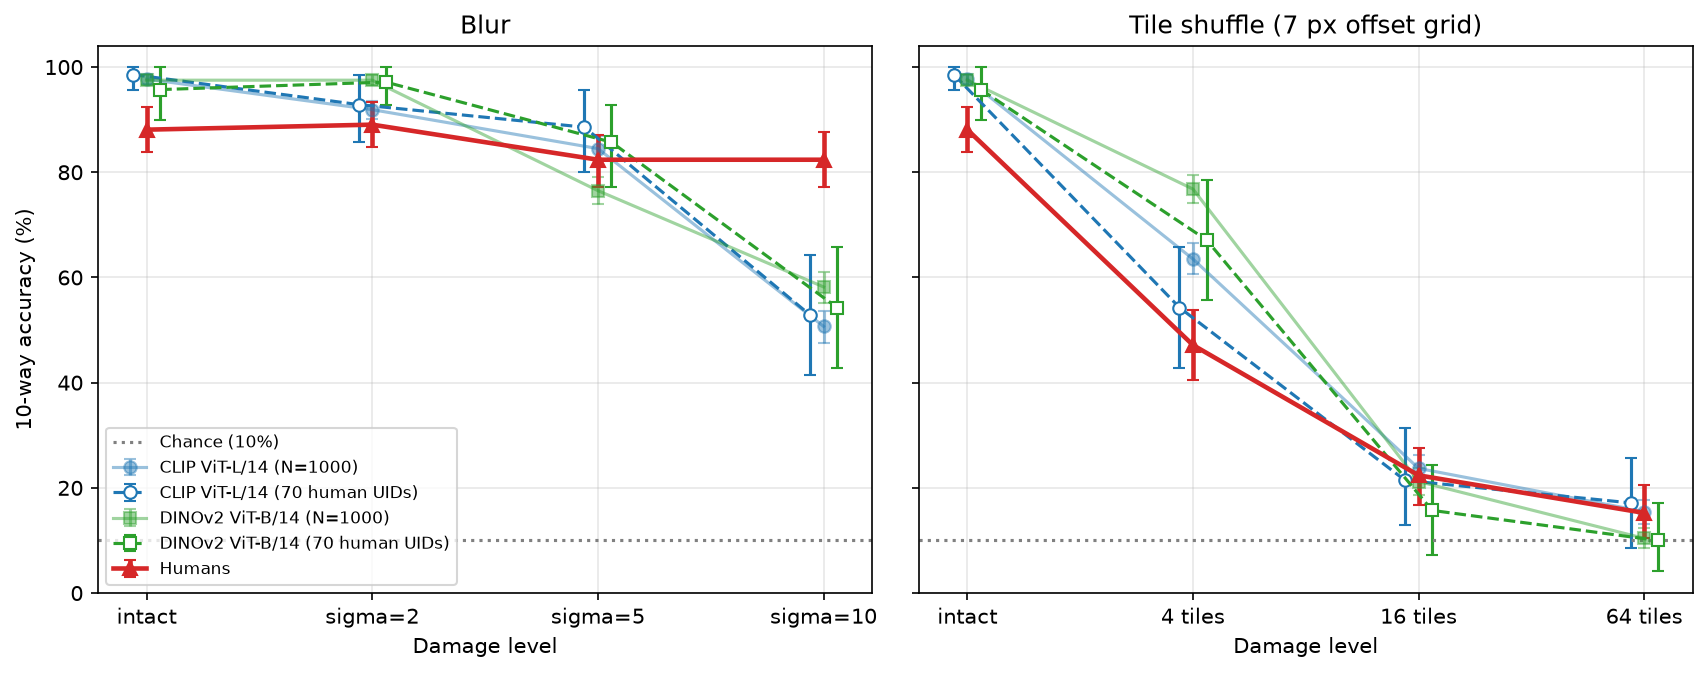

In [15]:
# ---- Main figure: two panels (Blur | Shuffle), accuracy vs damage level ----
LEVELS = ["low", "medium", "high"]
XLAB = {
    "blur":    ["intact"] + [f"sigma={BLUR_SIGMAS[l]}" for l in LEVELS],
    "shuffle": ["intact"] + [f"{SHUFFLE_GRIDS[l]**2} tiles" for l in LEVELS],
}
STYLE = {"CLIP ViT-L/14": ("tab:blue", "o"), "DINOv2 ViT-B/14": ("tab:green", "s")}

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharey=True)
for ax, fam in zip(axes, ["blur", "shuffle"]):
    conds = ["intact"] + [f"{fam}_{l}" for l in LEVELS]
    xs = np.arange(len(conds))
    for idx_m, (name, (col, mk)) in enumerate(STYLE.items()):
        offset = -0.06 if idx_m == 0 else 0.06
        d_full = results[results.model == name].set_index("condition").loc[conds]
        ax.errorbar(xs, d_full.accuracy, yerr=[d_full.accuracy - d_full.ci_low, d_full.ci_high - d_full.accuracy],
                    color=col, marker=mk, alpha=0.45, ls="-", capsize=3, label=f"{name} (N=1000)")
        d_sub = results_human70[results_human70.model == name].set_index("condition").loc[conds]
        ax.errorbar(xs + offset, d_sub.accuracy, yerr=[d_sub.accuracy - d_sub.ci_low, d_sub.ci_high - d_sub.accuracy],
                    color=col, marker=mk, mfc="white", ls="--", capsize=3, label=f"{name} (70 human UIDs)")
    if human is not None and not human.empty:
        h = human.set_index("condition").reindex(conds)
        valid = h["accuracy"].notna()
        ax.errorbar(xs[valid], h.loc[valid, "accuracy"],
                    yerr=[h.loc[valid, "accuracy"] - h.loc[valid, "ci_low"], h.loc[valid, "ci_high"] - h.loc[valid, "accuracy"]],
                    color="tab:red", marker="^", markersize=7, lw=2.2, ls="-", capsize=3, label="Humans")
    ax.axhline(10, color="grey", ls=":", label="Chance (10%)")
    ax.set_xticks(xs); ax.set_xticklabels(XLAB[fam]); ax.set_ylim(0, 104)
    ax.set_title("Blur" if fam == "blur" else "Tile shuffle (7 px offset grid)")
    ax.set_xlabel("Damage level"); ax.grid(alpha=0.3)
axes[0].set_ylabel("10-way accuracy (%)"); axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.savefig(OUT_DIR / "comparison_figure.png", dpi=200)
if human is not None and not human.empty:
    plt.savefig(OUT_DIR / "main_figure.png", dpi=200)
plt.show()

In [16]:
# ---- Diagnostics for the "expected failures" and "null result" sections of the proposal ----
# 1) Fraction of tiles containing ink in the shuffle conditions
ink = manifest[manifest.family == "shuffle"].groupby("condition").ink_tile_frac.agg(["mean", "min", "max"]).round(3)
print("Fraction of tiles that contain ink:\n", ink, "\n")

# 2) Accuracy of the hardest shuffle split by ink-tile fraction (below / above median)
mh = manifest[manifest.condition == "shuffle_high"].set_index("uid").ink_tile_frac
low_ink = (mh <= mh.median()).reindex(range(len(y_test))).values
for name in MODEL_SPECS:
    ok = (predict(name, FEATS[name]["shuffle_high"]) == y_test)
    print(f"{name} (N=1000): shuffle_high accuracy | few-ink-tiles {ok[low_ink].mean()*100:.1f}%  vs  many-ink-tiles {ok[~low_ink].mean()*100:.1f}%")

if "raw_human" in globals() and raw_human is not None and not raw_human.empty:
    sh_h = raw_human[raw_human["condition"] == "shuffle_high"].copy()
    sh_h["is_low_ink"] = sh_h["uid"].astype(int).map(lambda u: mh.loc[u] <= mh.median())
    print(f"Humans (N=21, 210 shuffle_high trials): shuffle_high accuracy | few-ink-tiles {sh_h[sh_h.is_low_ink]['correct'].mean()*100:.1f}%  vs  many-ink-tiles {sh_h[~sh_h.is_low_ink]['correct'].mean()*100:.1f}%")
    rt_summary = raw_human.groupby("condition")["rt_ms"].agg(median_ms="median", q25_ms=lambda s: s.quantile(0.25), q75_ms=lambda s: s.quantile(0.75)).loc[COND_NAMES].round(0)
    print("\nHuman Reaction Time (ms) by Condition:\n", rt_summary)

# 3) Resolution of the test: CI half-widths
hw = ((results.ci_high - results.ci_low) / 2).round(1)
print("\nMedian bootstrap CI half-width (percentage points):", hw.median(),
      "| max:", hw.max(), " (n =", int(results.n.iloc[0]), "test images per condition)")

Fraction of tiles that contain ink:
                  mean    min    max
condition                          
shuffle_high    0.448  0.203  0.734
shuffle_low     0.982  0.750  1.000
shuffle_medium  0.706  0.312  1.000 

CLIP ViT-L/14 (N=1000): shuffle_high accuracy | few-ink-tiles 21.1%  vs  many-ink-tiles 9.8%
DINOv2 ViT-B/14 (N=1000): shuffle_high accuracy | few-ink-tiles 15.1%  vs  many-ink-tiles 5.6%
Humans (N=21, 210 shuffle_high trials): shuffle_high accuracy | few-ink-tiles 13.7%  vs  many-ink-tiles 16.7%

Human Reaction Time (ms) by Condition:
                 median_ms  q25_ms  q75_ms
condition                                
intact              765.0   520.0  1397.0
blur_low            798.0   539.0  1277.0
blur_medium         942.0   581.0  1987.0
blur_high           943.0   570.0  1839.0
shuffle_low        1410.0   792.0  2956.0
shuffle_medium     1883.0   963.0  3042.0
shuffle_high       1630.0   779.0  3058.0

Median bootstrap CI half-width (percentage points): 2.4 | max: 

In [17]:
# ---- Package outputs ----
with zipfile.ZipFile("./project_outputs.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for f in OUT_DIR.rglob("*"):
        if f.is_file() and "stimuli_human/" not in str(f):
            z.write(f, f.relative_to(OUT_DIR))
print("Saved: model_results.csv, model_predictions.csv, stimuli_manifest.csv, human_trials.csv, stimuli_human.zip, probes, main_figure.png")
try:
    from google.colab import files
    files.download("./project_outputs.zip")
except Exception:
    pass

Saved: model_results.csv, model_predictions.csv, stimuli_manifest.csv, human_trials.csv, stimuli_human.zip, probes, main_figure.png


### How to use the outputs
* `stimuli_human.zip` + `human_trials.csv`: power the hosted web experiment (`index.html`). Each row says which PNG a participant sees on which trial and the correct label.
* After collecting human data (`responses_P01.csv` ... `responses_P12.csv`), place them in `human_logs/` and run `python analyze_results.py` (or re-run Section 6b above) to generate `human_results.csv`, evaluate models on the matched 70 `human_uids`, and overlay the Humans curve onto `main_figure.png` and `comparison_figure.png`.
* If ViTs stay near their intact accuracy under shuffling while humans collapse, the hypothesis is supported; if they drop as sharply as humans, it is contradicted. If the curves do not separate, report it as a null result with the CIs.